# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import OPTIMAL31Dataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/OPTIMAL-31/Images/",
    "csv_file": "./data/OPTIMAL-31/Images/train.csv",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = OPTIMAL31Dataset(dataset_config)

## Show images from the dataset

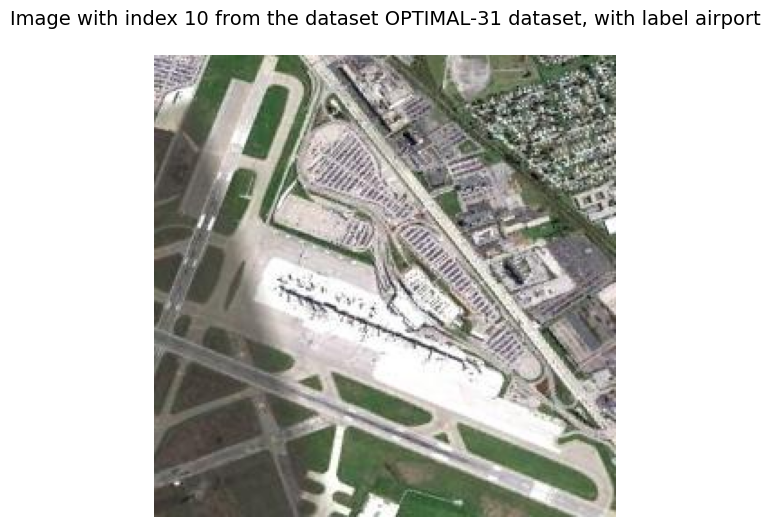

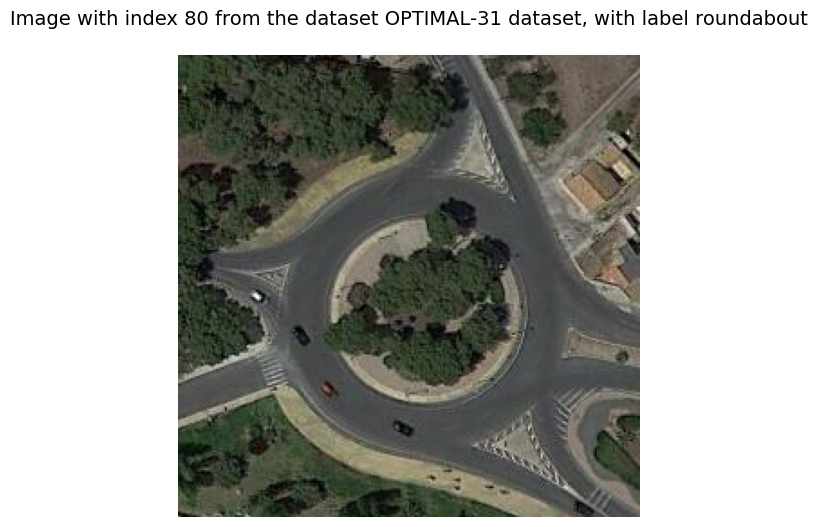

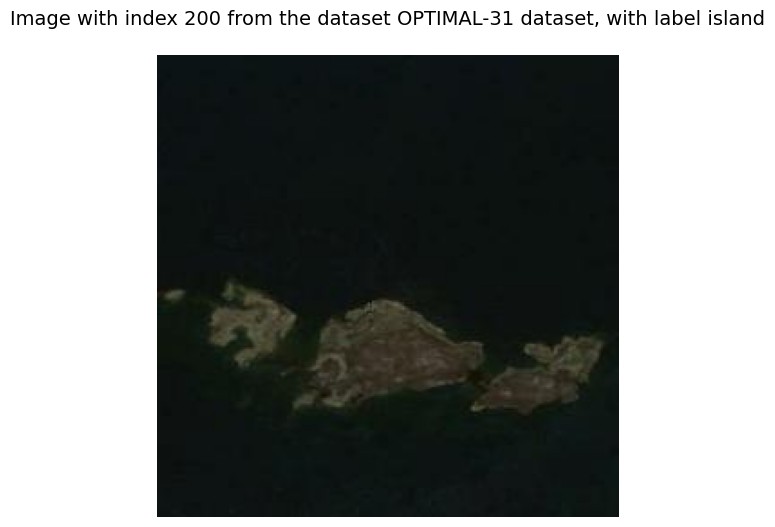

In [10]:
fig1 = dataset.show_image(10)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

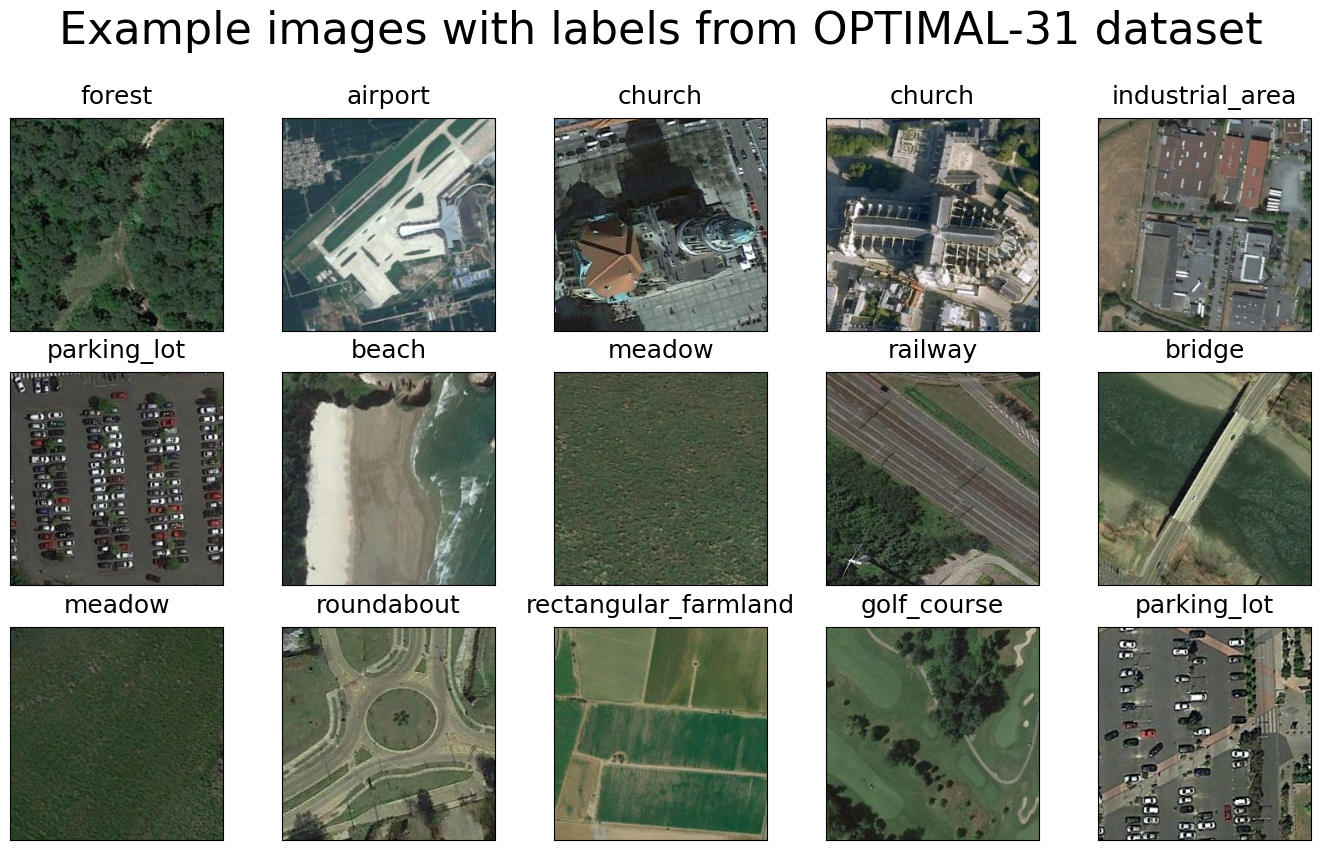

In [11]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [12]:
dataset.show_samples()

,File name,Label
0,chaparral/chaparral(30).jpg,chaparral
1,mountain/mountain(33).jpg,mountain
2,freeway/freeway(16).jpg,freeway
3,railway/railway(58).jpg,railway
4,circular_farmland/circular_farmland(8).jpg,circular_farmland
5,harbor/harbor(20).jpg,harbor
6,harbor/harbor(18).jpg,harbor
7,dense_residential/dense_residential(45).jpg,dense_residential
8,forest/forest(45).jpg,forest
9,mobile_home_park/mobile_home_park(56).jpg,mobile_home_park


In [13]:
dataset.data_distribution_table()

,Label,Count
0,airplane,51
1,airport,53
2,baseball_diamond,46
3,basketball_court,49
4,beach,48
5,bridge,51
6,chaparral,42
7,church,50
8,circular_farmland,49
9,commercial_area,48


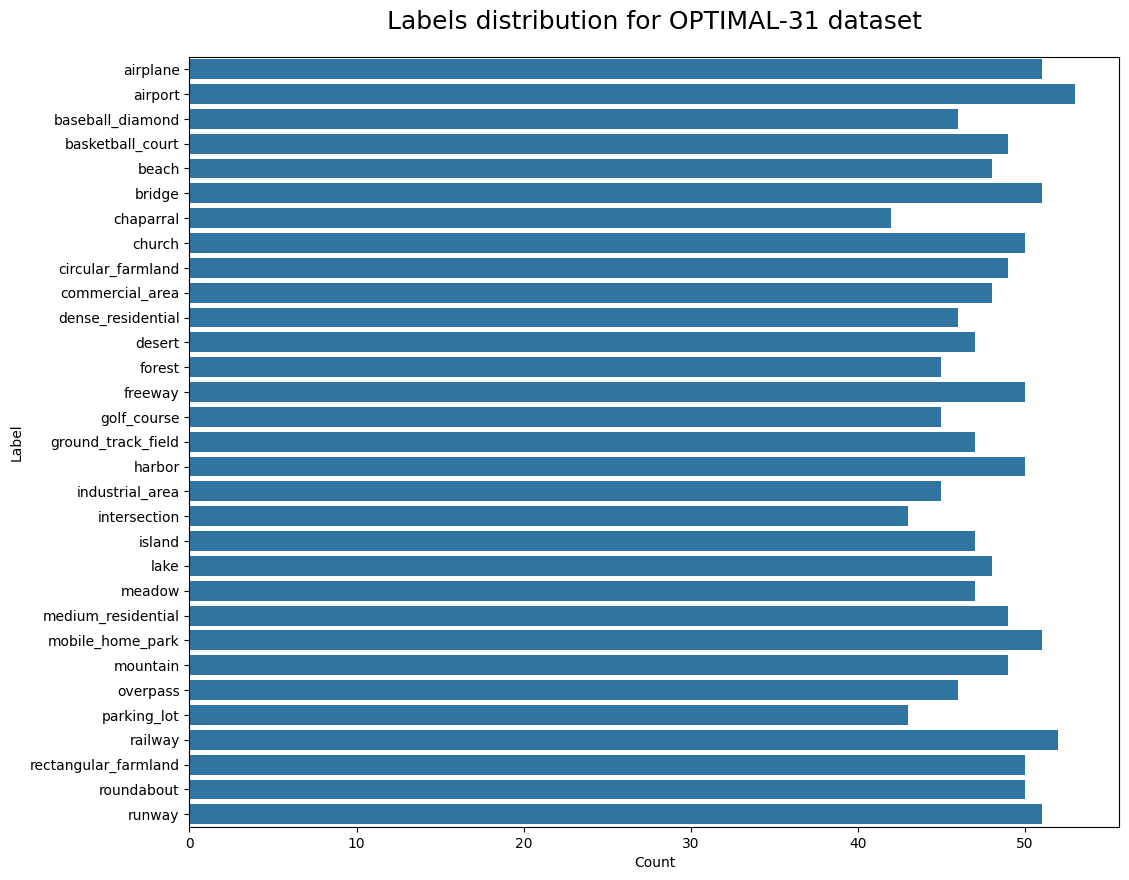

In [14]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/OPTIMAL-31/Images/",
    "csv_file": "./data/OPTIMAL-31/Images/train.csv",
}

train_dataset = OPTIMAL31Dataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/OPTIMAL-31/Images/",
    "csv_file": "./data/OPTIMAL-31/Images/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = OPTIMAL31Dataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(1488, 186)

## Setup and create the model for training

In [ ]:
epochs = 20
model_directory = "./data/experiments/OPTIMAL-31/"
model_config = {
    "num_classes": 31, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-15 07:18:16,817 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-15 07:18:16,946 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [18]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-15 07:18:18,798 INFO Starting training.
training: 100%|██████████| 47/47 [00:11<00:00,  3.98it/s]
2025-05-15 07:18:30,679 INFO epoch: 1, time: 12, loss:  2.81632
testing on train set: 100%|██████████| 47/47 [00:04<00:00, 10.86it/s]
2025-05-15 07:18:36,795 INFO Accuracy:0.7372311827956989, Precision Micro:0.7372311827956989, Precision Macro:0.7832745539899115, Precision Weighted:0.7830191291481075, Precision per Class:[0.92727273 0.42372881 0.7173913  0.68965517 0.9        0.92682927
 1.         0.73529412 0.9375     0.49090909 0.69230769 0.4893617
 0.975      0.9        0.6119403  0.77777778 0.9047619  0.85714286
 0.43333333 0.93023256 0.90243902 1.         0.86363636 0.62
 1.         0.80851064 0.70175439 0.64285714 0.9375     0.75
 0.734375  ], Recall Micro:0.7372311827956989, Recall Macro:0.7368818054366216, Recall Weighted:0.7372311827956989, Recall per Class:[1.         0.94339623 0.7173913  0.81632653 0.9375     0.74509804
 0.85714286 0.5        0.91836735 0.5625     0.78

0.0028372773736645217

## Test the model

In [ ]:

test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/OPTIMAL-31/Images/",
    "csv_file": "./data/OPTIMAL-31/Images/test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = OPTIMAL31Dataset(test_dataset_config)
model_path = "./data/experiments/OPTIMAL-31/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-15 07:22:51,613 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/OPTIMAL-31/checkpoint.pth.tar
2025-05-15 07:22:51,852 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/OPTIMAL-31/checkpoint.pth.tar at epoch 21
testing on test set: 100%|██████████| 12/12 [00:01<00:00, 10.87it/s]


[{'Accuracy': 0.9247311827956989},
 {'Precision Micro': 0.9247311827956989,
  'Precision Macro': 0.9254608294930874,
  'Precision Weighted': 0.931048387096774,
  'Precision per Class': array([1.        , 0.8       , 1.        , 1.        , 1.        ,
         1.        , 1.        , 0.875     , 1.        , 0.85714286,
         1.        , 1.        , 1.        , 0.75      , 1.        ,
         1.        , 0.75      , 1.        , 0.9       , 1.        ,
         0.85714286, 1.        , 1.        , 0.6       , 1.        ,
         0.75      , 1.        , 1.        , 0.8       , 1.        ,
         0.75      ])},
 {'Recall Micro': 0.9247311827956989,
  'Recall Macro': 0.9309907834101381,
  'Recall Weighted': 0.9247311827956988,
  'Recall per Class': array([1.        , 1.        , 1.        , 1.        , 1.        ,
         0.75      , 1.        , 1.        , 1.        , 0.85714286,
         1.        , 0.8       , 1.        , 1.        , 1.        ,
         0.85714286, 1.        , 0.

## Predictions

2025-05-15 07:28:14,590 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/OPTIMAL-31/checkpoint.pth.tar
2025-05-15 07:28:14,803 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/OPTIMAL-31/checkpoint.pth.tar at epoch 21


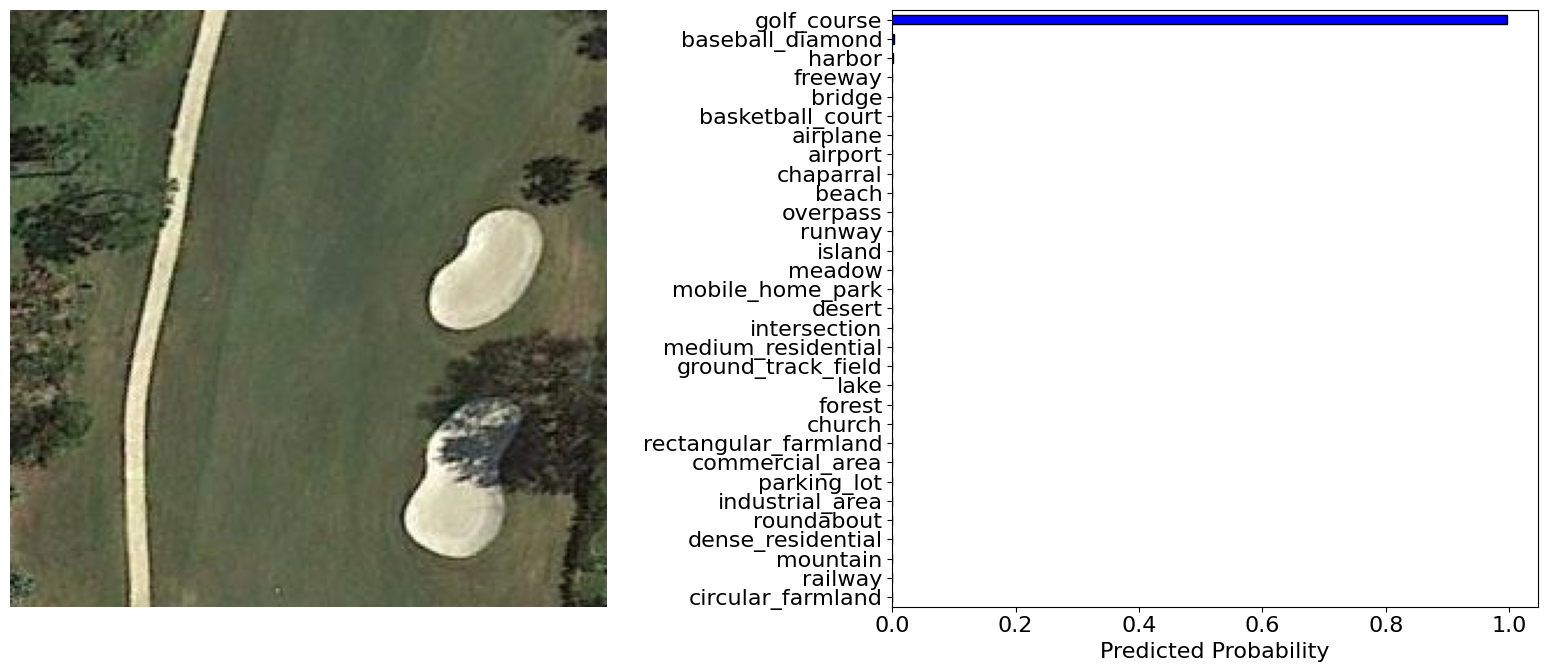

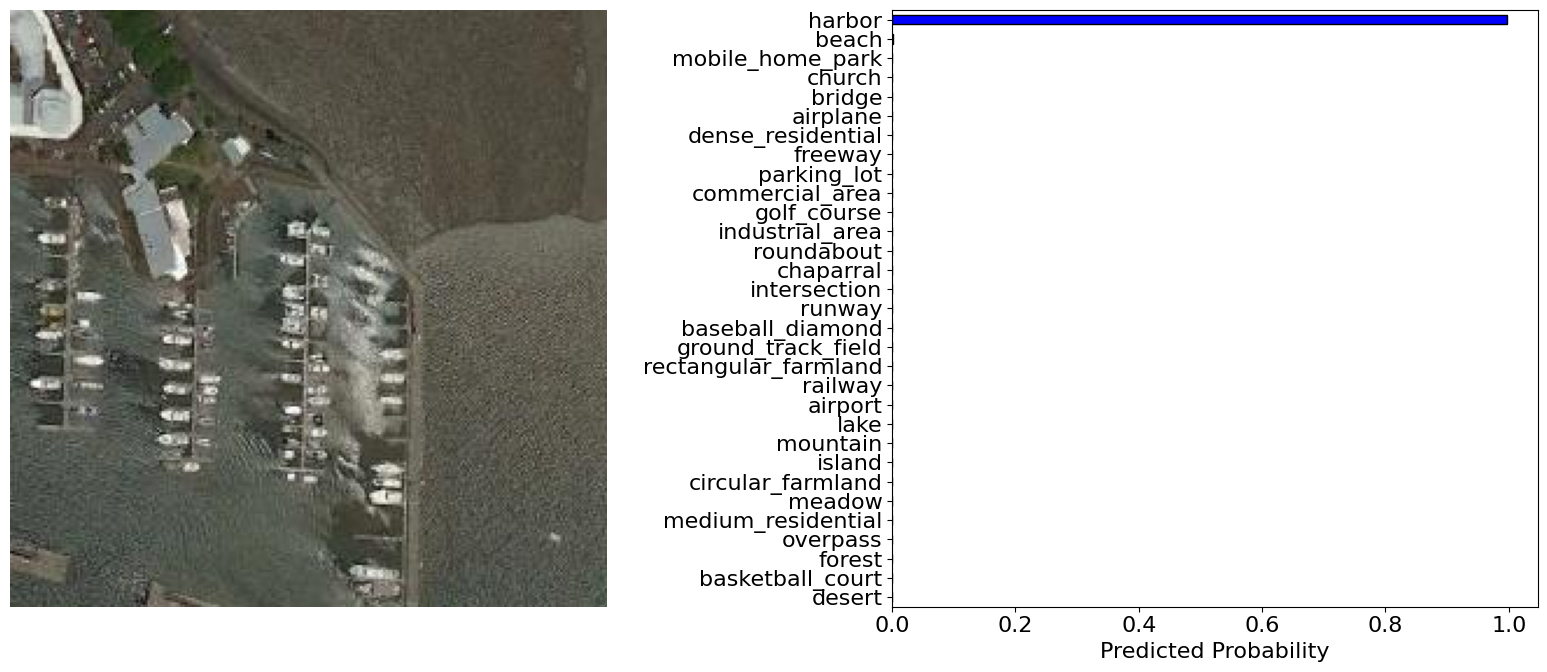

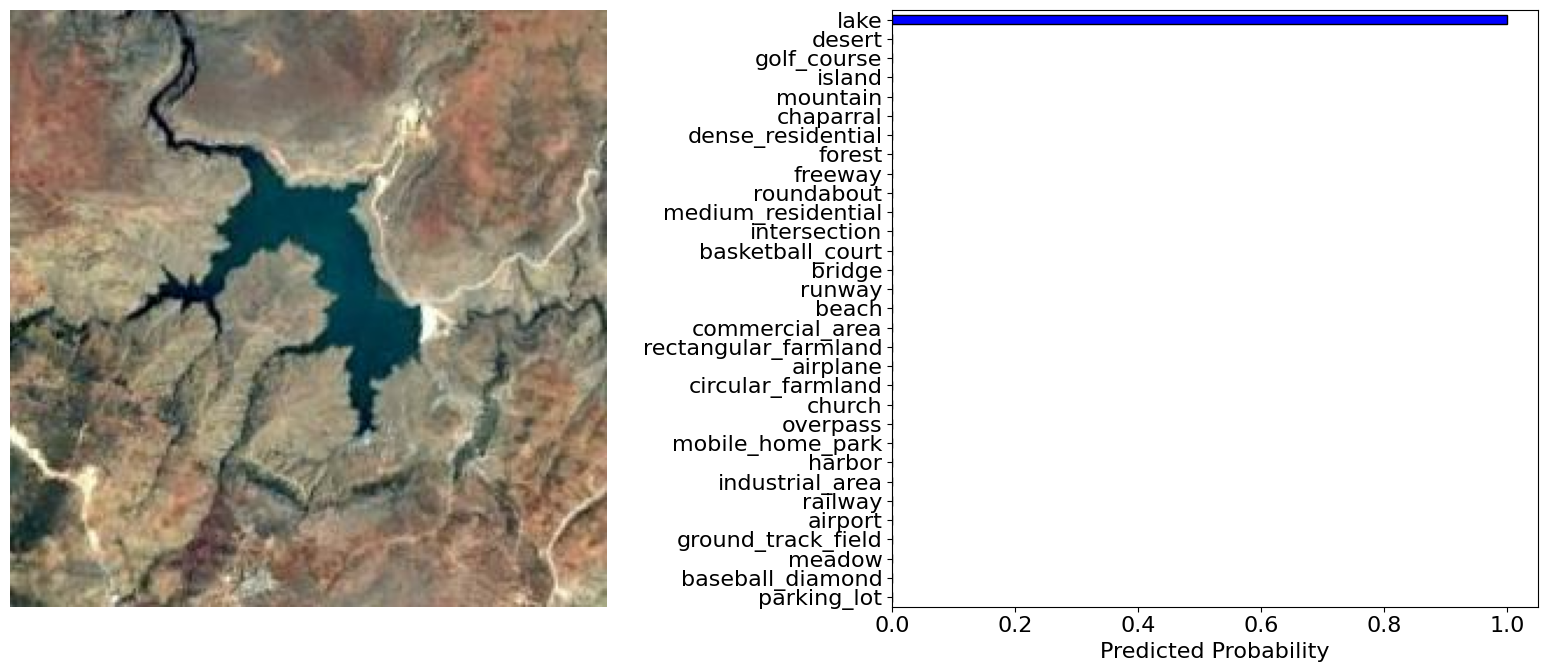

In [ ]:
labels = ["airplane","airport","baseball_diamond","basketball_court","beach","bridge","chaparral",
          "church","circular_farmland","commercial_area","dense_residential","desert","forest","freeway",
          "golf_course","ground_track_field","harbor","industrial_area","intersection","island","lake",
          "meadow","medium_residential","mobile_home_park","mountain","overpass","parking_lot","railway",
          "rectangular_farmland","roundabout","runway"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/OPTIMAL-31/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/OPTIMAL-31/Images/golf_course/golf_course(60).jpg')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/OPTIMAL-31/Images/harbor/harbor(16).jpg')
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/OPTIMAL-31/Images/lake/lake(43).jpg')
fig = model.predict_image(image, labels, transform)